In [1]:
import os
os.makedirs("/tmp/nlm", exist_ok=True)
!wget -q --show-progress https://data.lhncbc.nlm.nih.gov/public/Malaria/Thick_Smears_150/ThickBloodSmears_150.zip -O /tmp/nlm/thick150.zip
!unzip -q /tmp/nlm/thick150.zip -d /tmp/nlm/data
!du -sh /tmp/nlm/data

/tmp/nlm/thick150.z 100%[===================>]   3.65G   152MB/s    in 25s     
3.8G	/tmp/nlm/data


In [2]:
from pathlib import Path
from collections import Counter

root = Path("/tmp/nlm/data")
files = [p for p in root.rglob("*") if p.is_file()]
print("Total files:", len(files))
print("By type:", Counter(p.suffix.lower() for p in files))

for p in sorted(root.iterdir()):
    print(p.name)
    if p.is_dir():
        subs = sorted(p.iterdir())
        for s in subs[:5]:
            print("   ", s.name)
        print("    ... total", len(subs))

first_txt = sorted(p for p in files if p.suffix.lower() == ".txt")[0]
print("\nExample annotation:", first_txt)
print(first_txt.read_text()[:800])

Total files: 3735
By type: Counter({'.jpg': 1883, '.txt': 1830, '.db': 21, '.docx': 1})
GT_updated
    TF100_CS39
    TF101_233
    TF102_234
    TF103_235
    TF104_240
    ... total 150
ReadMe_new_2021.docx
TF100_CS39
    20170829_205107.jpg
    20170829_205324.jpg
    20170829_205527.jpg
    20170829_205620.jpg
    20170829_205809.jpg
    ... total 15
TF101_233
    20170830_103930.jpg
    20170830_104154.jpg
    20170830_104309.jpg
    20170830_104418.jpg
    20170830_104521.jpg
    ... total 14
TF102_234
    20170830_110101.jpg
    20170830_110200.jpg
    20170830_110450.jpg
    20170830_110608.jpg
    20170830_110803.jpg
    ... total 22
TF103_235
    20170830_113418.jpg
    20170830_113814.jpg
    20170830_114242.jpg
    20170830_114554.jpg
    20170830_115138.jpg
    ... total 5
TF104_240
    20170830_122033.jpg
    20170830_132254.jpg
    20170830_132515.jpg
    20170830_132615.jpg
    20170830_132710.jpg
    ... total 12
TF105_245
    20170830_140427.jpg
    20170830_140604.jp

In [3]:
import pandas as pd, numpy as np
from pathlib import Path

data = Path("/tmp/nlm/data"); gt = data / "GT_updated"
SHAPES = {"Circle", "Point", "Polygon", "Rectangle", "Line"}

imgs = {(p.parent.name, p.stem): p for p in data.glob("TF*/*.jpg")}
txts = {(p.parent.name, p.stem): p for p in gt.glob("TF*/*.txt")}
print("Images:", len(imgs), "| Annotation files:", len(txts))
print("Images with no annotation file:", len(set(imgs) - set(txts)))
print("Annotation files with no image:", len(set(txts) - set(imgs)))

rows, headers, bad = [], [], []
for (pat, stem), t in txts.items():
    lines = t.read_text().strip().splitlines()
    n, h, w = [int(float(v)) for v in lines[0].split(",")[:3]]
    headers.append(dict(patient=pat, image=stem, n_header=n, h=h, w=w, n_lines=len(lines) - 1))
    for line in lines[1:]:
        parts = [s.strip() for s in line.split(",")]
        i = next((k for k in range(2, len(parts) - 1) if parts[k] in SHAPES and parts[k + 1].isdigit()), None)
        if i is None:
            bad.append(line); continue
        npts = int(parts[i + 1]); xy = list(map(float, parts[i + 2:i + 2 + 2 * npts]))
        r = np.hypot(xy[2] - xy[0], xy[3] - xy[1]) if parts[i] == "Circle" and npts >= 2 else np.nan
        rows.append(dict(patient=pat, image=stem, label=parts[1], comment=",".join(parts[2:i]),
                         shape=parts[i], x=xy[0], y=xy[1], r=r))

ann = pd.DataFrame(rows); hdr = pd.DataFrame(headers)
print("\nObjects read:", len(ann), "| Lines that could not be read:", len(bad), bad[:3])
print("Files where header count = number of lines:", round((hdr.n_header == hdr.n_lines).mean() * 100, 1), "%")
print("\n", pd.crosstab(ann.label, ann["shape"]))
print("\nComments:\n", ann.comment.value_counts().head(10))
print("\nImage sizes in headers:\n", hdr.groupby(["h", "w"]).size())

Images: 1883 | Annotation files: 1830
Images with no annotation file: 53
Annotation files with no image: 0

Objects read: 119958 | Lines that could not be read: 0 []
Files where header count = number of lines: 98.9 %

 shape             Circle  Point
label                          
Parasite           84509      0
White_Blood_Cell       0  35449

Comments:
 comment
No_Comment           117655
troph                  1685
schizont                396
schi                    149
gam                      58
trophozoite               4
Early_trophozoite         3
Early_schizont            2
gametocyte                1
troh                      1
Name: count, dtype: int64

Image sizes in headers:
 h     w   
4032  3024    1830
dtype: int64


In [4]:
from PIL import Image

chk = []
for _, r in hdr.sample(40, random_state=0).iterrows():
    im = Image.open(imgs[(r.patient, r.image)])
    chk.append(f"stored (w,h)={im.size}  header (h,w)=({r.h},{r.w})  rotate-flag={im.getexif().get(274, 1)}")
print(pd.Series(chk).value_counts(), "\n")

per_img = (ann.groupby(["patient", "image", "label"]).size().unstack(fill_value=0)
              .reindex(columns=["Parasite", "White_Blood_Cell"], fill_value=0).reset_index())
per_pat = per_img.groupby("patient")[["Parasite", "White_Blood_Cell"]].sum()
per_pat["images"] = per_img.groupby("patient").size()
per_pat["density_per_uL"] = per_pat.Parasite / per_pat.White_Blood_Cell * 8000
print(per_pat.describe().round(1))
print("\nPatients with fewer than 200 WBCs counted:", (per_pat.White_Blood_Cell < 200).sum(), "of", len(per_pat))
print("Images with zero WBCs:", (per_img.White_Blood_Cell == 0).sum(), "of", len(per_img))
print("\nParasite circle radius (pixels):\n", ann.r.describe().round(1))

ann.to_csv("/kaggle/working/nlm_annotations.csv", index=False)
per_pat.to_csv("/kaggle/working/nlm_per_patient.csv")

stored (w,h)=(4032, 3024)  header (h,w)=(4032,3024)  rotate-flag=6    40
Name: count, dtype: int64 

label  Parasite  White_Blood_Cell  images  density_per_uL
count     150.0             150.0   150.0           150.0
mean      563.4             236.3    12.2         20279.9
std       728.2              35.6     4.0         26990.5
min         9.0             184.0     4.0           283.0
25%        91.0             221.0    10.0          2965.2
50%       235.5             230.0    12.0          8253.7
75%       627.2             240.0    15.0         21600.7
max      3315.0             526.0    22.0        124080.0

Patients with fewer than 200 WBCs counted: 2 of 150
Images with zero WBCs: 0 of 1830

Parasite circle radius (pixels):
 count    84509.0
mean        21.2
std          4.9
min          1.5
25%         17.9
50%         20.8
75%         24.0
max         95.6
Name: r, dtype: float64


In [5]:
print("x range:", round(ann.x.min()), "to", round(ann.x.max()))
print("y range:", round(ann.y.min()), "to", round(ann.y.max()))

mm = hdr[hdr.n_header != hdr.n_lines]
print("\nFiles where header count differs from lines:", len(mm))
print(mm.assign(diff=mm.n_lines - mm.n_header).head(10).to_string(index=False))

x range: 584 to 3877
y range: 36 to 2998

Files where header count differs from lines: 20
   patient           image  n_header    h    w  n_lines  diff
TF121_1581 20170831_103804       213 4032 3024      212    -1
TF121_1581 20170831_104551       196 4032 3024      195    -1
 TF57_CV11 20170813_102928       186 4032 3024      185    -1
TF30_W13B1 20170724_144325       200 4032 3024      199    -1
TF30_W13B1 20170724_145845       266 4032 3024      265    -1
TF125_S537 20170831_141322       185 4032 3024      184    -1
  TF3N_536 20171023_132712        87 4032 3024       86    -1
TF134_US28 20170831_202541        28 4032 3024       27    -1
TF134_US28 20170831_203023        25 4032 3024       24    -1
 TF99_CS40 20170829_203106        30 4032 3024       29    -1


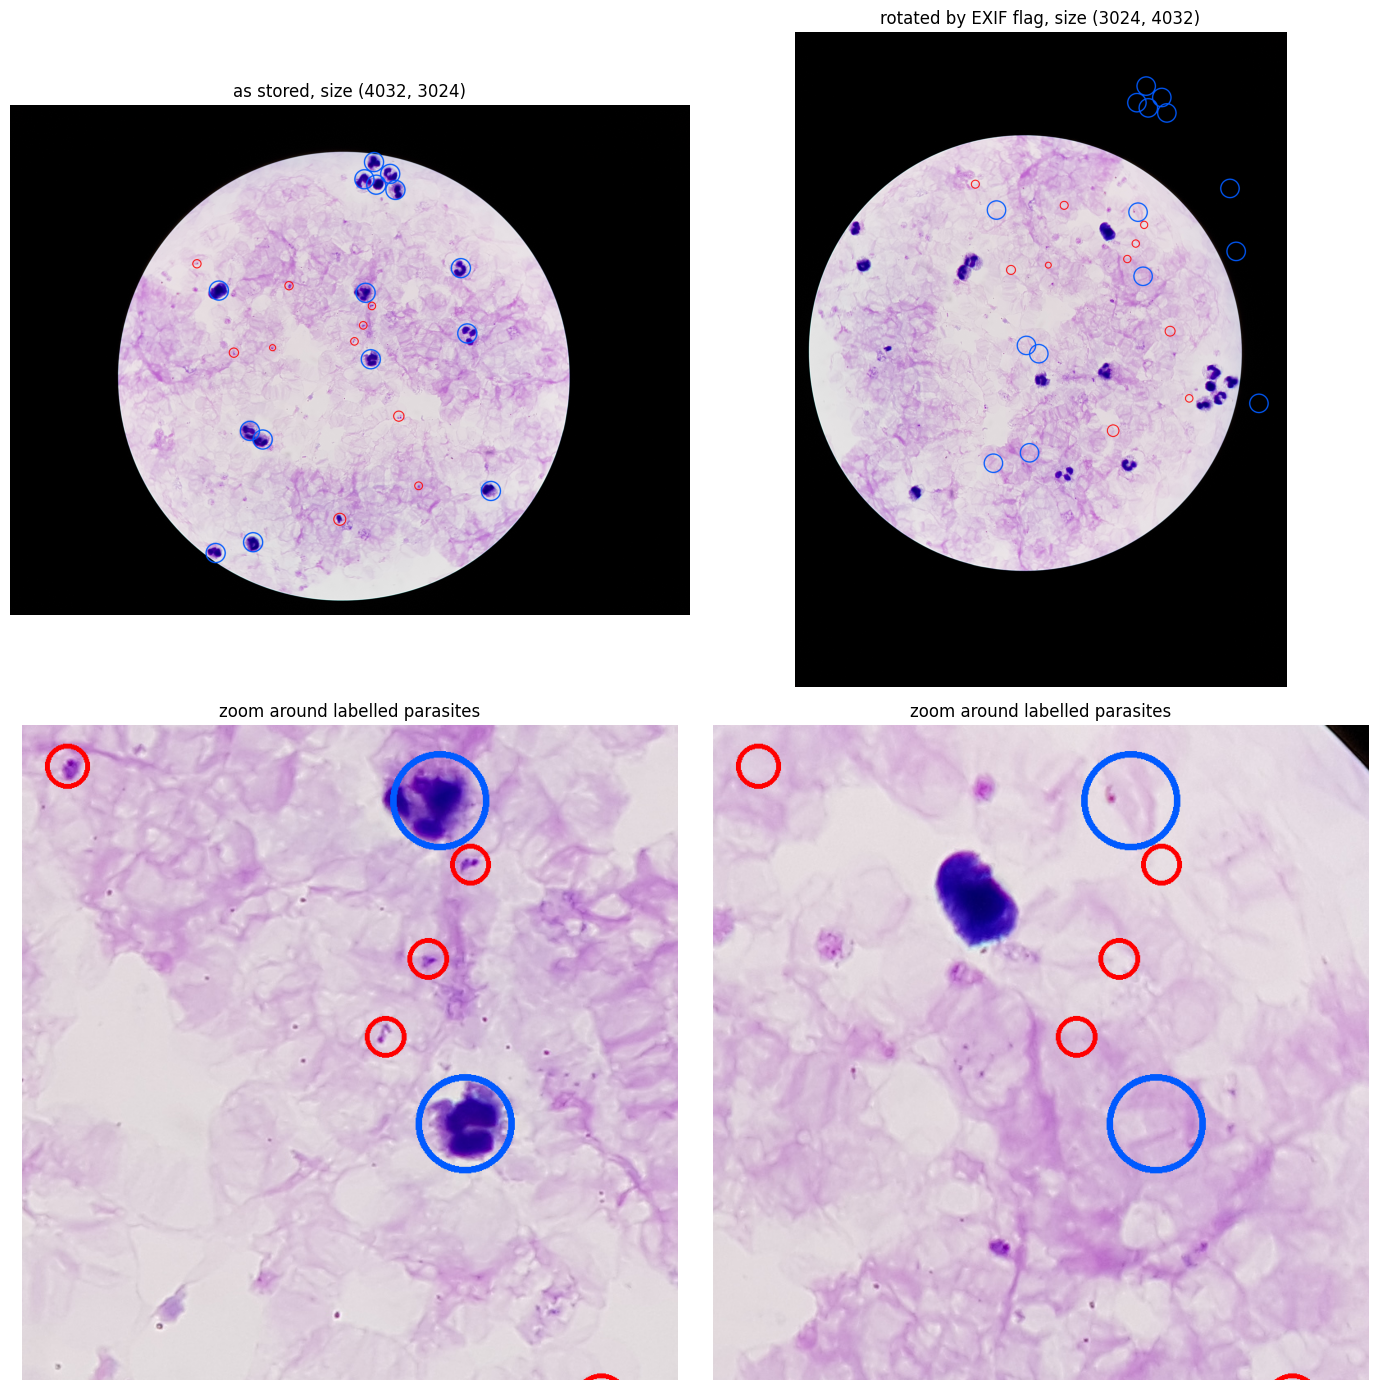

In [6]:
from PIL import ImageOps, ImageDraw
import matplotlib.pyplot as plt

key = ("TF100_CS39", "20170829_205107")
a = ann[(ann.patient == key[0]) & (ann.image == key[1])]
versions = {"as stored": Image.open(imgs[key]).convert("RGB"),
            "rotated by EXIF flag": ImageOps.exif_transpose(Image.open(imgs[key])).convert("RGB")}

px, py = a[a.label == "Parasite"][["x", "y"]].median()   
fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for col, (title, im) in enumerate(versions.items()):
    im = im.copy(); d = ImageDraw.Draw(im)
    for _, o in a.iterrows():
        if o.label == "Parasite":
            d.ellipse([o.x - o.r - 6, o.y - o.r - 6, o.x + o.r + 6, o.y + o.r + 6], outline=(255, 0, 0), width=6)
        else:
            d.ellipse([o.x - 60, o.y - 60, o.x + 60, o.y + 60], outline=(0, 90, 255), width=8)
    axes[0, col].imshow(im); axes[0, col].set_title(f"{title}, size {im.size}")
    axes[1, col].imshow(im.crop((int(px) - 400, int(py) - 400, int(px) + 400, int(py) + 400)))
    axes[1, col].set_title("zoom around labelled parasites")
    for ax in axes[:, col]: ax.axis("off")
plt.tight_layout(); plt.show()

In [7]:
rng = np.random.default_rng(42)
ann["half"] = np.where(ann.label == "Parasite", ann.r.clip(lower=10) + 4, 60.0) 
ann["cls"] = (ann.label == "White_Blood_Cell").astype(int)      

per_pat["band"] = pd.qcut(per_pat.density_per_uL, 3, labels=["low", "mid", "high"])
split = {}
for band, g in per_pat.groupby("band", observed=True):
    pats = rng.permutation(g.index.to_numpy())
    n_test, n_val = round(len(pats) * 0.20), round(len(pats) * 0.133)
    for p in pats[:n_test]: split[p] = "test"
    for p in pats[n_test:n_test + n_val]: split[p] = "val"
    for p in pats[n_test + n_val:]: split[p] = "train"
per_pat["split"] = per_pat.index.map(split)

print(per_pat.groupby(["split", "band"], observed=True).size().unstack())
print("\nMedian density per split:\n", per_pat.groupby("split").density_per_uL.median().round(0))
ann.to_csv("/kaggle/working/nlm_annotations.csv", index=False)
per_pat.to_csv("/kaggle/working/nlm_per_patient.csv")

band   low  mid  high
split                
test    10   10    10
train   33   33    33
val      7    7     7

Median density per split:
 split
test     9077.0
train    8292.0
val      6000.0
Name: density_per_uL, dtype: float64


In [8]:
import yaml
OUT = Path("/kaggle/working/nlm_tiles"); S, T, STEP = 0.5, 640, 544   
for sp in ["train", "val", "test"]:
    for sub in ["images", "labels"]:
        (OUT / sp / sub).mkdir(parents=True, exist_ok=True)

stats = []
for (pat, stem), a in ann.groupby(["patient", "image"]):     
    sp = split[pat]
    im = Image.open(imgs[(pat, stem)]).convert("RGB")    
    W, H = int(im.width * S), int(im.height * S)
    arr = np.asarray(im.resize((W, H), Image.BILINEAR))
    cx, cy, hr, c = a.x.to_numpy() * S, a.y.to_numpy() * S, a.half.to_numpy() * S, a.cls.to_numpy()
    for x0 in list(range(0, W - T, STEP)) + [W - T]:
        for y0 in list(range(0, H - T, STEP)) + [H - T]:
            tile = arr[y0:y0 + T, x0:x0 + T]
            if (tile.mean(axis=2) < 40).mean() > 0.6:     
                continue
            lines = []
            for k in np.where((cx >= x0) & (cx < x0 + T) & (cy >= y0) & (cy < y0 + T))[0]:
                x1, x2 = max(cx[k] - hr[k], x0), min(cx[k] + hr[k], x0 + T)
                y1, y2 = max(cy[k] - hr[k], y0), min(cy[k] + hr[k], y0 + T)
                lines.append(f"{c[k]} {((x1+x2)/2-x0)/T:.6f} {((y1+y2)/2-y0)/T:.6f} {(x2-x1)/T:.6f} {(y2-y1)/T:.6f}")
            name = f"{pat}__{stem}__{x0}_{y0}"
            Image.fromarray(tile).save(OUT / sp / "images" / f"{name}.jpg", quality=92)  
            (OUT / sp / "labels" / f"{name}.txt").write_text("\n".join(lines))
            stats.append((sp, len(lines)))

yaml.safe_dump({"path": str(OUT), "train": "train/images", "val": "val/images", "test": "test/images",
                "names": {0: "parasite", 1: "wbc"}}, open(OUT / "data.yaml", "w"))
st = pd.DataFrame(stats, columns=["split", "objects"])
print(st.groupby("split").agg(tiles=("objects", "size"), objects=("objects", "sum"),
                              empty_tiles=("objects", lambda s: (s == 0).sum())))
!du -sh /kaggle/working/nlm_tiles

       tiles  objects  empty_tiles
split                             
test    2845    37096           27
train   8689   120877           84
val     1965    28907           22
799M	/kaggle/working/nlm_tiles


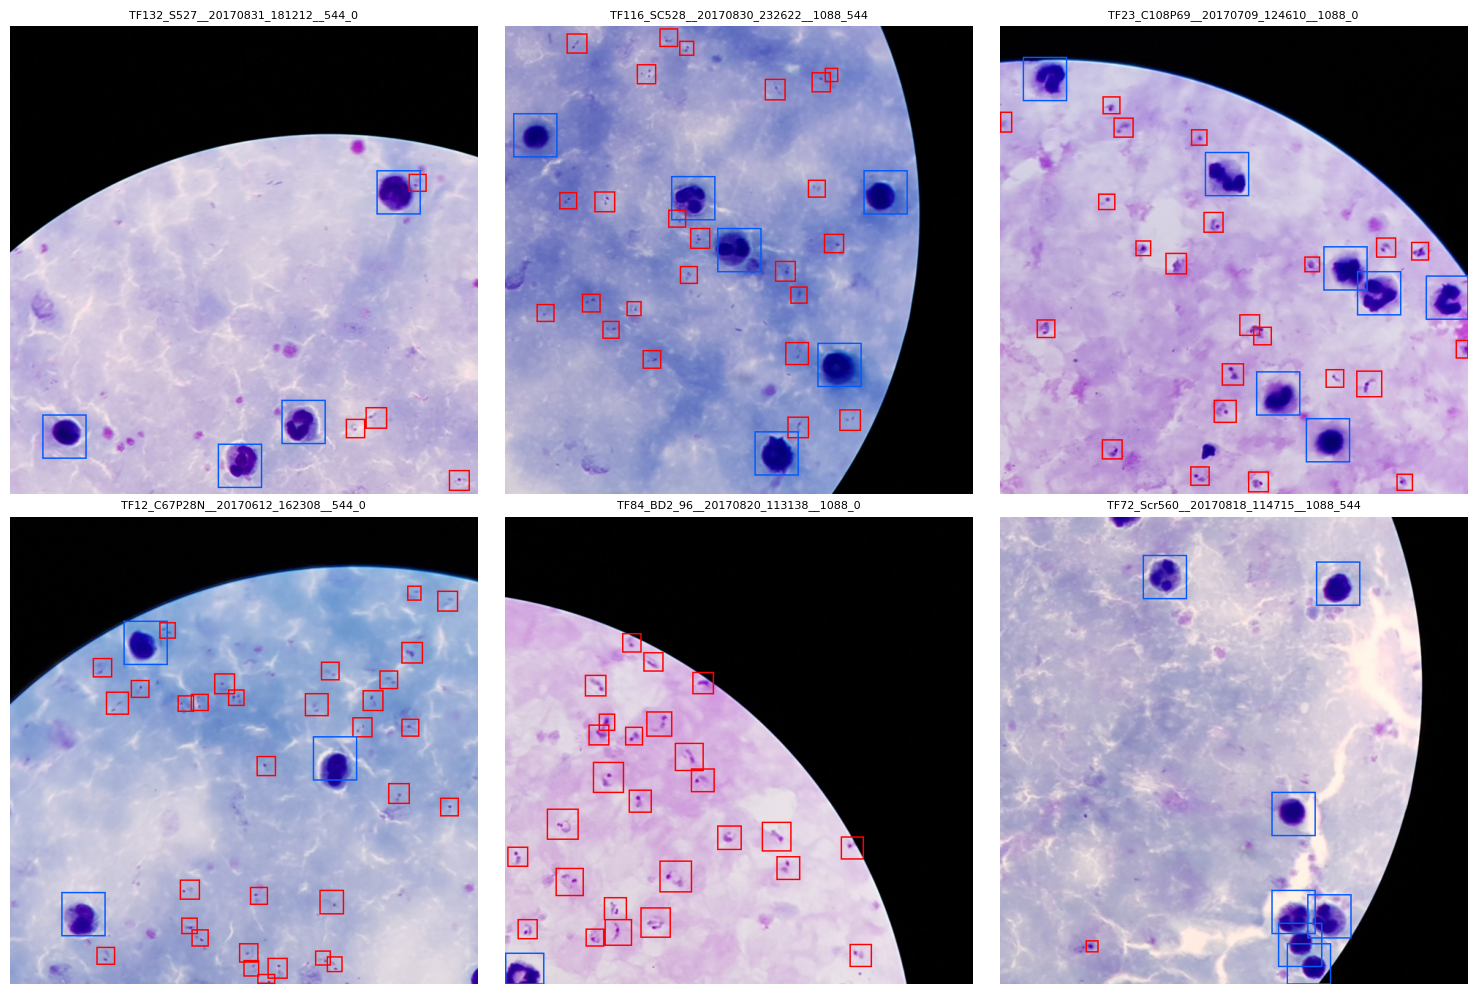

In [9]:
import random
from PIL import ImageDraw
random.seed(1)
picks = random.sample(sorted((OUT / "train" / "images").glob("*.jpg")), 6)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, p in zip(axes.flat, picks):
    im = Image.open(p).convert("RGB"); d = ImageDraw.Draw(im)
    for line in (OUT / "train" / "labels" / f"{p.stem}.txt").read_text().splitlines():
        c, xc, yc, w, h = map(float, line.split())
        x1, y1, x2, y2 = (xc - w/2) * T, (yc - h/2) * T, (xc + w/2) * T, (yc + h/2) * T
        d.rectangle([x1, y1, x2, y2], outline=(255, 0, 0) if c == 0 else (0, 90, 255), width=2)
    ax.imshow(im); ax.set_title(p.stem[:40], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()